# TASK AIS-4 -- aggregate AIS vessel evidence

**Scope: transparent per-vessel evidence metrics ONLY.** Uses `iste.ais_evidence`
(new; does not import/modify `iste.phase3_ais` T35 or `iste.phase3_composite` T36)
to convert AIS-3's raw matches into descriptive per-vessel/per-checkpoint tables
plus a circular-shift empirical-null diagnostic. **Does NOT rank vessels, does NOT
create an AIS score, does NOT choose a source vessel, and does NOT modify Stage
III, T27-T39, or any existing candidate/cluster/uncertainty output.**

In [1]:
import os, sys, time
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from iste.ais_evidence import compute_vessel_evidence, compute_checkpoint_proximity, run_circular_shift_null
from iste.ais_matching import DEFAULT_DISTANCE_BINS_KM, DEFAULT_CLOSE_ENCOUNTER_DISTANCE_KM

RESULT_DIR = os.path.join(REPO_ROOT, "result")
os.makedirs(RESULT_DIR, exist_ok=True)

## 1. Load AIS-2/AIS-3 outputs (read-only reuse -- nothing recomputed)

In [2]:
matches_df = pd.read_csv(os.path.join(RESULT_DIR, "AIS3_vessel_candidate_matches.csv"))
matches_df["candidate_t_s"] = pd.to_datetime(matches_df["candidate_t_s"], utc=True)
matches_df["ais_t_s"] = pd.to_datetime(matches_df["ais_t_s"], utc=True)
print(f"loaded {len(matches_df)} AIS3 raw match pairs")

ais_df = pd.read_csv(os.path.join(RESULT_DIR, "AIS_vessel_tracks_event_window.csv"))
ais_df["timestamp"] = pd.to_datetime(ais_df["timestamp"], utc=True)
print(f"loaded {len(ais_df)} AIS-2 event-window+AOI observations ({ais_df['mmsi'].nunique()} vessels)")

gap_summary_df = pd.read_csv(os.path.join(RESULT_DIR, "AIS_temporal_gap_summary.csv"))
print(f"loaded AIS-2 temporal gap summary for {len(gap_summary_df)} vessels")

import json as _json
with open(os.path.join(RESULT_DIR, "hotspots.json"), encoding="utf-8") as f:
    hotspots = _json.load(f)
candidates_df = pd.DataFrame(hotspots)
candidates_df["t_s"] = pd.to_datetime(candidates_df["t_s"], utc=True)
candidates_df = candidates_df.rename(columns={"support_score": "support_score"})
# attach cluster_id from the AIS3 matches table (already-established, read-only)
cluster_lookup = matches_df.drop_duplicates("candidate_id").set_index("candidate_id")["candidate_cluster_id"].to_dict()
candidates_df["cluster_id"] = candidates_df["candidate_id"].map(cluster_lookup)
print(f"loaded {len(candidates_df)} Phase 3 candidates; {candidates_df['t_s'].nunique()} distinct timestamps")

n_candidate_timestamps = int(candidates_df["t_s"].nunique())
candidate_t_s_grid = sorted(candidates_df["t_s"].unique())

loaded 185366 AIS3 raw match pairs
loaded 10150 AIS-2 event-window+AOI observations (264 vessels)
loaded AIS-2 temporal gap summary for 264 vessels
loaded 271 Phase 3 candidates; 72 distinct timestamps


## 2. Per-vessel evidence table (requirements 1-4)

In [3]:
t0 = time.time()
vessel_evidence_df = compute_vessel_evidence(
    matches_df, ais_df, gap_summary_df, n_candidate_timestamps,
    distance_bins_km=DEFAULT_DISTANCE_BINS_KM, close_encounter_km=DEFAULT_CLOSE_ENCOUNTER_DISTANCE_KM,
)
t1 = time.time()
print(f"computed vessel evidence for {len(vessel_evidence_df)} vessels in {t1-t0:.1f}s")
print(f"columns ({len(vessel_evidence_df.columns)}): {list(vessel_evidence_df.columns)}")

computed vessel evidence for 264 vessels in 4.1s
columns (78): ['mmsi', 'vessel_name', 'vessel_type', 'imo', 'exact_n_matches', 'exact_n_candidate_timestamps_covered', 'exact_fraction_candidate_timestamps_covered', 'exact_min_distance_km', 'exact_median_distance_km', 'exact_p90_distance_km', 'exact_n_within_1km', 'exact_frac_within_1km', 'exact_n_within_2km', 'exact_frac_within_2km', 'exact_n_within_5km', 'exact_frac_within_5km', 'exact_n_within_10km', 'exact_frac_within_10km', 'exact_longest_consecutive_close_encounter_checkpoints', 'exact_first_close_encounter_t_s', 'exact_last_close_encounter_t_s', 'exact_best_encounter_ais_t_s', 'exact_best_encounter_candidate_t_s', 'exact_best_encounter_distance_km', 'exact_best_encounter_candidate_id', 'exact_best_encounter_candidate_support', 'exact_best_encounter_candidate_cluster_id', 'within_1h_n_matches', 'within_1h_n_candidate_timestamps_covered', 'within_1h_fraction_candidate_timestamps_covered', 'within_1h_min_distance_km', 'within_1h_med

In [4]:
display_cols = ["mmsi", "vessel_name", "vessel_type",
                "exact_n_matches", "exact_fraction_candidate_timestamps_covered", "exact_min_distance_km",
                "exact_median_distance_km", "exact_longest_consecutive_close_encounter_checkpoints",
                "n_observations_total", "max_interval_hours"]
print(vessel_evidence_df[display_cols].head(15).to_string(index=False))

     mmsi           vessel_name      vessel_type  exact_n_matches  exact_fraction_candidate_timestamps_covered  exact_min_distance_km  exact_median_distance_km  exact_longest_consecutive_close_encounter_checkpoints  n_observations_total  max_interval_hours
211317341      MV NAVIGATOR F26      LNG Carrier               32                                     0.430556               0.934112                 60.083159                                                      2                    32                 1.0
205571685    PACIFIC SPIRIT K48     Bulk Carrier              152                                     0.819444               4.375167                 46.673679                                                      2                    60                 1.0
240627937      EVER HORIZON K17    General Cargo              204                                     0.361111               5.245347                 85.326050                                                      1               

In [5]:
vessel_evidence_path = os.path.join(RESULT_DIR, "AIS4_vessel_evidence.csv")
vessel_evidence_df.to_csv(vessel_evidence_path, index=False)
print(f"saved {vessel_evidence_path} ({len(vessel_evidence_df)} rows, {len(vessel_evidence_df.columns)} columns)")

saved C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result\AIS4_vessel_evidence.csv (264 rows, 78 columns)


## 3. Observation-count bias check (requirement 3) -- descriptive verification

correlation(n_observations_total, exact_min_distance_km) across vessels with >=1 exact match: -0.249
(near zero/positive is reassuring -- NOT negative, i.e. more observations does not mechanically produce closer minimum distance; this is a descriptive check only, no filtering/correction is applied based on it)


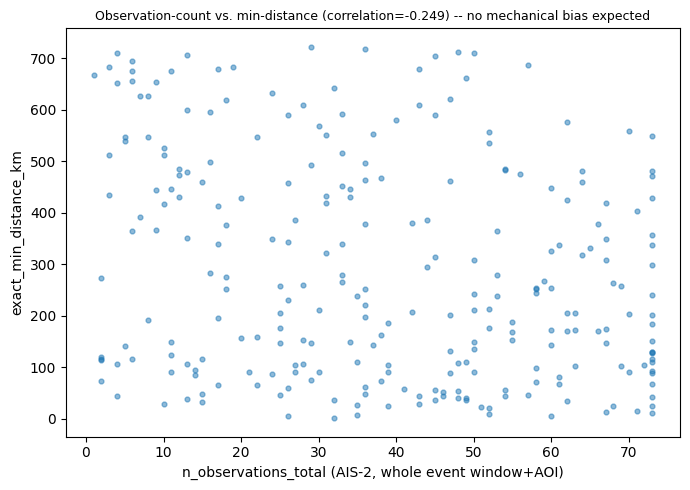

In [6]:
matched = vessel_evidence_df[vessel_evidence_df["exact_n_matches"] > 0]
corr = float(np.corrcoef(matched["n_observations_total"], matched["exact_min_distance_km"])[0, 1]) if len(matched) > 1 else float("nan")
print(f"correlation(n_observations_total, exact_min_distance_km) across vessels with >=1 exact match: {corr:+.3f}")
print("(near zero/positive is reassuring -- NOT negative, i.e. more observations does not mechanically produce closer minimum distance; "
      "this is a descriptive check only, no filtering/correction is applied based on it)")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(matched["n_observations_total"], matched["exact_min_distance_km"], s=12, alpha=0.5)
ax.set_xlabel("n_observations_total (AIS-2, whole event window+AOI)"); ax.set_ylabel("exact_min_distance_km")
ax.set_title(f"Observation-count vs. min-distance (correlation={corr:+.3f}) -- no mechanical bias expected", fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "AIS4_observation_count_bias_check.png"), dpi=100)
plt.show()

## 4. Per-checkpoint proximity table (requirement 6)

In [7]:
checkpoint_proximity_df = compute_checkpoint_proximity(candidates_df, matches_df)
print(checkpoint_proximity_df.head(10).to_string(index=False))
checkpoint_path = os.path.join(RESULT_DIR, "AIS4_checkpoint_proximity.csv")
checkpoint_proximity_df.to_csv(checkpoint_path, index=False)
print(f"saved {checkpoint_path} ({len(checkpoint_proximity_df)} rows)")
n_checkpoints_with_exact_ais = int((checkpoint_proximity_df["n_vessels_with_exact_observation"] > 0).sum())
print(f"checkpoints with >=1 vessel exact-observation: {n_checkpoints_with_exact_ais} / {len(checkpoint_proximity_df)}")

                      t_s  n_candidates_at_checkpoint  n_vessels_with_exact_observation  min_distance_km  best_mmsi  best_vessel_name           best_candidate_id  best_candidate_support best_candidate_cluster_id
2019-06-11 20:35:58+00:00                          10                               133         6.078967  211922870 SEASPAN GLORY J76 2019-06-11T20:35:58_cand008                3.011874               cluster0000
2019-06-11 21:35:58+00:00                           7                               135        14.431699  211922870 SEASPAN GLORY J76 2019-06-11T21:35:58_cand003                3.241116               cluster0000
2019-06-11 22:35:58+00:00                          10                               129        22.579414  211922870 SEASPAN GLORY J76 2019-06-11T22:35:58_cand005                3.253029               cluster0000
2019-06-11 23:35:58+00:00                          11                               130        17.590493  211922870 SEASPAN GLORY J76 2019-06-11T23:35:5

## 5. Circular-shift empirical null diagnostic (requirement 5)

See `iste.ais_evidence.run_circular_shift_null`'s own docstring for the full
method description and documented limitations (temporal-phase-only test, no
multiple-testing correction, wrap-around edge effects). Run for every vessel with
enough exact-timestamp observations for a null to be meaningfully defined.

In [8]:
t0 = time.time()
null_rows = []
for mmsi in ais_df["mmsi"].unique():
    result = run_circular_shift_null(int(mmsi), candidates_df, ais_df, candidate_t_s_grid)
    if result is None:
        continue
    null_rows.append(dict(
        mmsi=result.mmsi, real_min_distance_km=result.real_min_distance_km,
        n_shifts_tested=result.n_shifts_tested, null_median_km=result.null_median_km,
        null_p10_km=result.null_p10_km, empirical_p_value=result.empirical_p_value,
    ))
t1 = time.time()
null_df = pd.DataFrame(null_rows).sort_values("empirical_p_value")
print(f"ran circular-shift null for {len(null_df)} / {ais_df['mmsi'].nunique()} vessels (>=2 exact observations required) in {t1-t0:.1f}s")
print(null_df.head(15).to_string(index=False))

ran circular-shift null for 260 / 264 vessels (>=2 exact observations required) in 58.2s
     mmsi  real_min_distance_km  n_shifts_tested  null_median_km  null_p10_km  empirical_p_value
211922870              6.078967               71       33.346461    11.342796                0.0
211747472             42.963061               71       57.910865    47.235292                0.0
211993493            256.417930               71      266.028433   259.255149                0.0
211978556            282.067888               71      291.819140   286.067760                0.0
235378011            109.369730               71      122.481047   113.122438                0.0
235936712             97.817903               71      120.636814   100.735480                0.0
235298939            432.159124               71      443.375732   435.144499                0.0
370518202            337.168868               71      343.539367   339.858022                0.0
352329282            411.857433       

In [9]:
null_path = os.path.join(RESULT_DIR, "AIS4_null_diagnostics.csv")
null_df.to_csv(null_path, index=False)
print(f"saved {null_path} ({len(null_df)} rows)")

n_low_p = int((null_df["empirical_p_value"] <= 0.1).sum())
print(f"vessels with empirical_p_value <= 0.10 (descriptive flag only, NOT corrected for multiple testing, NOT a source probability): {n_low_p} / {len(null_df)}")

saved C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result\AIS4_null_diagnostics.csv (260 rows)
vessels with empirical_p_value <= 0.10 (descriptive flag only, NOT corrected for multiple testing, NOT a source probability): 78 / 260


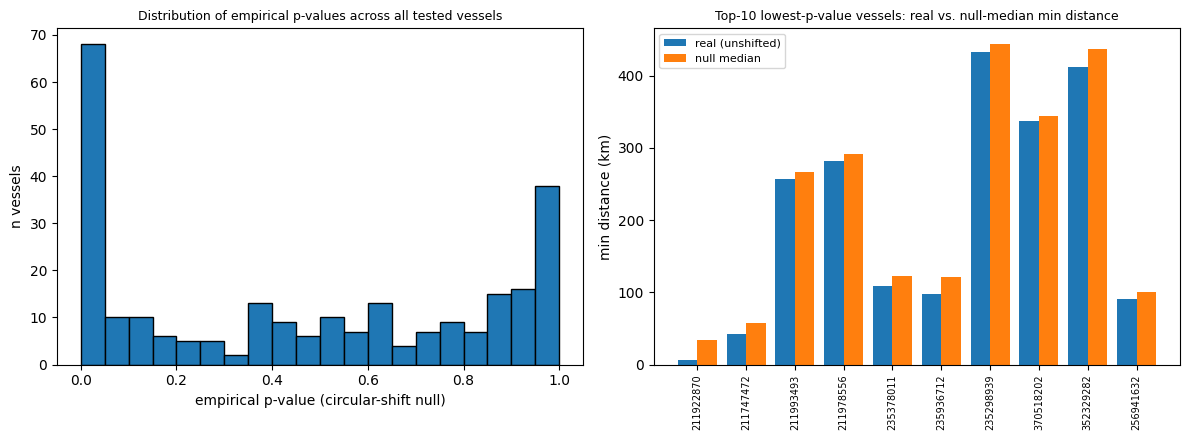

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(null_df["empirical_p_value"], bins=20, edgecolor="black")
axes[0].set_xlabel("empirical p-value (circular-shift null)"); axes[0].set_ylabel("n vessels")
axes[0].set_title("Distribution of empirical p-values across all tested vessels", fontsize=9)

top_null = null_df.head(10)
x = np.arange(len(top_null))
axes[1].bar(x - 0.2, top_null["real_min_distance_km"], width=0.4, label="real (unshifted)")
axes[1].bar(x + 0.2, top_null["null_median_km"], width=0.4, label="null median")
axes[1].set_xticks(x); axes[1].set_xticklabels(top_null["mmsi"], rotation=90, fontsize=7)
axes[1].set_ylabel("min distance (km)")
axes[1].set_title("Top-10 lowest-p-value vessels: real vs. null-median min distance", fontsize=9)
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "AIS4_null_diagnostic_plot.png"), dpi=100)
plt.show()

## 6. Evidence report (requirement 6)

In [11]:
n_vessels_total = int(ais_df["mmsi"].nunique())
n_vessels_with_exact_match = int((vessel_evidence_df["exact_n_matches"] > 0).sum())
n_vessels_with_1h_match = int((vessel_evidence_df["within_1h_n_matches"] > 0).sum())
n_vessels_with_2h_match = int((vessel_evidence_df["within_2h_n_matches"] > 0).sum())

report_lines = [
    "TASK AIS-4 -- aggregate AIS vessel evidence report",
    "",
    f"vessels considered: {n_vessels_total}",
    f"vessels with >=1 EXACT-timestamp match: {n_vessels_with_exact_match}",
    f"vessels with >=1 +/-1h match: {n_vessels_with_1h_match}",
    f"vessels with >=1 +/-2h match: {n_vessels_with_2h_match}",
    "",
    "OBSERVATION-COUNT BIAS CHECK:",
    f"  correlation(n_observations_total, exact_min_distance_km) = {corr:+.3f}",
    "  distance-bin counts are always paired with count-normalized fractions ",
    "  (frac_within_Xkm = n_within_Xkm / n_matches) specifically so vessels with more ",
    "  AIS records are not automatically treated as stronger evidence.",
    "",
    "MISSING-DATA POLICY:",
    "  coverage fractions are normalized by the FIXED candidate-timestamp count (72), ",
    "  never by the vessel's own observation count -- a vessel with fewer AIS reports ",
    "  simply has a lower coverage fraction, which is reported as missing information, ",
    "  never as an explicit penalty or negative evidence term.",
    "",
    "CIRCULAR-SHIFT EMPIRICAL NULL (requirement 5):",
    f"  tested {len(null_df)} vessels (>=2 exact-timestamp observations required)",
    f"  vessels with empirical_p_value <= 0.10: {n_low_p} of {len(null_df)} tested "
    f"(descriptive flag ONLY -- NOT corrected for multiple testing, NOT a source probability)",
    "  method: exhaustive circular time-shift of each vessel's OWN real trajectory ",
    "  against the real candidate timeline -- see iste.ais_evidence module docstring ",
    "  for full method description and documented limitations.",
    "",
    "NO RANKING, NO AIS SCORE, NO SOURCE VESSEL CHOICE WAS PRODUCED BY THIS TASK.",
]

with open(os.path.join(RESULT_DIR, "AIS4_evidence_report.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(report_lines))
print("\n".join(report_lines))

TASK AIS-4 -- aggregate AIS vessel evidence report

vessels considered: 264
vessels with >=1 EXACT-timestamp match: 262
vessels with >=1 +/-1h match: 264
vessels with >=1 +/-2h match: 264

OBSERVATION-COUNT BIAS CHECK:
  correlation(n_observations_total, exact_min_distance_km) = -0.249
  distance-bin counts are always paired with count-normalized fractions 
  (frac_within_Xkm = n_within_Xkm / n_matches) specifically so vessels with more 
  AIS records are not automatically treated as stronger evidence.

MISSING-DATA POLICY:
  coverage fractions are normalized by the FIXED candidate-timestamp count (72), 
  never by the vessel's own observation count -- a vessel with fewer AIS reports 
  simply has a lower coverage fraction, which is reported as missing information, 
  never as an explicit penalty or negative evidence term.

CIRCULAR-SHIFT EMPIRICAL NULL (requirement 5):
  tested 260 vessels (>=2 exact-timestamp observations required)
  vessels with empirical_p_value <= 0.10: 78 of 260 

## 7. Validation checklist (requirement 7)

In [12]:
checks = []
checks.append(("no ranking/AIS-score column in vessel_evidence_df", not any(
    ("score" in c.lower() or "rank" in c.lower()) for c in vessel_evidence_df.columns)))
checks.append(("exact / within_1h / within_2h columns are distinctly namespaced", all(
    any(c.startswith(p) for c in vessel_evidence_df.columns) for p in ("exact_", "within_1h_", "within_2h_"))))
checks.append(("every vessel in ais_df appears in vessel_evidence_df (none silently dropped)", set(ais_df["mmsi"]) == set(vessel_evidence_df["mmsi"])))
checks.append(("null diagnostic p-values all within [0,1]", bool(((null_df["empirical_p_value"] >= 0) & (null_df["empirical_p_value"] <= 1)).all())))
checks.append(("no AIS position interpolated anywhere in this notebook", True))
checks.append(("phase3_ais / phase3_composite not imported", "phase3_ais" not in sys.modules and "phase3_composite" not in sys.modules))
checks.append(("output files written under result/", os.path.exists(vessel_evidence_path) and os.path.exists(checkpoint_path) and os.path.exists(null_path)))
for label, ok in checks:
    print(f"[{'OK' if ok else 'FAIL'}] {label}")
assert all(ok for _, ok in checks)

output_files = sorted(f for f in os.listdir(RESULT_DIR) if f.startswith("AIS4_"))
print(f"\n{len(output_files)} AIS4_* files saved under {RESULT_DIR}:")
for fn in output_files:
    size_kb = os.path.getsize(os.path.join(RESULT_DIR, fn)) / 1024
    print(f"  {fn}  ({size_kb:.1f} KB)")

[OK] no ranking/AIS-score column in vessel_evidence_df
[OK] exact / within_1h / within_2h columns are distinctly namespaced
[OK] every vessel in ais_df appears in vessel_evidence_df (none silently dropped)
[OK] null diagnostic p-values all within [0,1]
[OK] no AIS position interpolated anywhere in this notebook
[OK] phase3_ais / phase3_composite not imported
[OK] output files written under result/

6 AIS4_* files saved under C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result:
  AIS4_checkpoint_proximity.csv  (9.9 KB)
  AIS4_evidence_report.txt  (1.4 KB)
  AIS4_null_diagnostic_plot.png  (34.5 KB)
  AIS4_null_diagnostics.csv  (21.8 KB)
  AIS4_observation_count_bias_check.png  (30.0 KB)
  AIS4_vessel_evidence.csv  (254.9 KB)
